# Lista de Exercícios
## Preparação dos Dados e Análise de Desempenho de Modelos
@Autor: Rodrigo Baptista de Barros

@Numero Usp: 12562010

In [20]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [21]:
base = pd.read_excel("soja_milho (3).xlsx", skiprows=7)

In [22]:
base

,Observação,Data,Mês,Ano - Safra,Preços - Milho,Preços - Soja
0,1,02/01/2014,1,2014,26.64,72.18
1,2,03/01/2014,1,2014,27.00,71.42
2,3,06/01/2014,1,2014,27.29,71.38
3,4,07/01/2014,1,2014,27.49,70.31
4,5,08/01/2014,1,2014,27.16,70.14
...,...,...,...,...,...,...
493,494,22/12/2015,12,2015,36.23,78.61
494,495,23/12/2015,12,2015,36.26,78.21
495,496,28/12/2015,12,2015,36.29,77.59
496,497,29/12/2015,12,2015,36.55,78.55


In [23]:
base_predicted = base.copy()
base_real = base.copy()

In [24]:
condicoes_predicted1 = (base["Ano - Safra"] == 2014) & (base["Preços - Soja"] >= 67.00)
condicoes_predicted2 = (base["Ano - Safra"] == 2015) & (base["Preços - Soja"] >= 58.00) & (base["Preços - Soja"] <= 62.00)

In [25]:
base_predicted["Estágio"] = np.where(condicoes_predicted1|condicoes_predicted2, "Colheita", "Plantio")

In [26]:
base_predicted

,Observação,Data,Mês,Ano - Safra,Preços - Milho,Preços - Soja,Estágio
0,1,02/01/2014,1,2014,26.64,72.18,Colheita
1,2,03/01/2014,1,2014,27.00,71.42,Colheita
2,3,06/01/2014,1,2014,27.29,71.38,Colheita
3,4,07/01/2014,1,2014,27.49,70.31,Colheita
4,5,08/01/2014,1,2014,27.16,70.14,Colheita
...,...,...,...,...,...,...,...
493,494,22/12/2015,12,2015,36.23,78.61,Plantio
494,495,23/12/2015,12,2015,36.26,78.21,Plantio
495,496,28/12/2015,12,2015,36.29,77.59,Plantio
496,497,29/12/2015,12,2015,36.55,78.55,Plantio


In [27]:
condicoes_real = (base["Mês"] <= 5)

In [28]:
base_real["Estágio"] = np.where(condicoes_real, "Colheita", "Plantio")

In [29]:
base_real

,Observação,Data,Mês,Ano - Safra,Preços - Milho,Preços - Soja,Estágio
0,1,02/01/2014,1,2014,26.64,72.18,Colheita
1,2,03/01/2014,1,2014,27.00,71.42,Colheita
2,3,06/01/2014,1,2014,27.29,71.38,Colheita
3,4,07/01/2014,1,2014,27.49,70.31,Colheita
4,5,08/01/2014,1,2014,27.16,70.14,Colheita
...,...,...,...,...,...,...,...
493,494,22/12/2015,12,2015,36.23,78.61,Plantio
494,495,23/12/2015,12,2015,36.26,78.21,Plantio
495,496,28/12/2015,12,2015,36.29,77.59,Plantio
496,497,29/12/2015,12,2015,36.55,78.55,Plantio


In [30]:
from sklearn.model_selection import train_test_split

### AS MATRIZES ANTERIORES FORAM FEITAS SOMENTE PARA CUMPRIR O PROPÓSITO DO EXERCÍCIO DE CRIAR O "MODELO" E O "REAL". VOU COLOCAR TUDO NA BASE DE DADOS INICIAL.

In [38]:
base["Estágio Previsto"] = base_predicted["Estágio"]
base["Estágio Real"] = base_real["Estágio"]

In [39]:
base

,Observação,Data,Mês,Ano - Safra,Preços - Milho,Preços - Soja,Estágio Previsto,Estágio Real
0,1,02/01/2014,1,2014,26.64,72.18,Colheita,Colheita
1,2,03/01/2014,1,2014,27.00,71.42,Colheita,Colheita
2,3,06/01/2014,1,2014,27.29,71.38,Colheita,Colheita
3,4,07/01/2014,1,2014,27.49,70.31,Colheita,Colheita
4,5,08/01/2014,1,2014,27.16,70.14,Colheita,Colheita
...,...,...,...,...,...,...,...,...
493,494,22/12/2015,12,2015,36.23,78.61,Plantio,Plantio
494,495,23/12/2015,12,2015,36.26,78.21,Plantio,Plantio
495,496,28/12/2015,12,2015,36.29,77.59,Plantio,Plantio
496,497,29/12/2015,12,2015,36.55,78.55,Plantio,Plantio


In [40]:
soja_real = base["Estágio Real"]
soja_real

0      Colheita
1      Colheita
2      Colheita
3      Colheita
4      Colheita
         ...   
493     Plantio
494     Plantio
495     Plantio
496     Plantio
497     Plantio
Name: Estágio Real, Length: 498, dtype: object

In [41]:
soja_treino, soja_teste = train_test_split(base, test_size = 0.25, random_state = 1, stratify=soja_real)

In [42]:
soja_treino

,Observação,Data,Mês,Ano - Safra,Preços - Milho,Preços - Soja,Estágio Previsto,Estágio Real
104,105,04/06/2014,6,2014,27.33,69.30,Colheita,Plantio
28,29,11/02/2014,2,2014,28.93,65.52,Plantio,Colheita
477,478,30/11/2015,11,2015,33.25,76.65,Plantio,Plantio
136,137,22/07/2014,7,2014,22.99,61.83,Plantio,Plantio
332,333,05/05/2015,5,2015,25.82,63.70,Plantio,Colheita
...,...,...,...,...,...,...,...,...
31,32,14/02/2014,2,2014,30.11,67.76,Colheita,Colheita
127,128,08/07/2014,7,2014,24.48,64.84,Plantio,Plantio
407,408,19/08/2015,8,2015,27.34,70.96,Plantio,Plantio
399,400,07/08/2015,8,2015,27.60,73.18,Plantio,Plantio


In [43]:
soja_teste

,Observação,Data,Mês,Ano - Safra,Preços - Milho,Preços - Soja,Estágio Previsto,Estágio Real
118,119,25/06/2014,6,2014,25.48,67.02,Colheita,Plantio
50,51,17/03/2014,3,2014,33.37,68.50,Colheita,Colheita
495,496,28/12/2015,12,2015,36.29,77.59,Plantio,Plantio
8,9,14/01/2014,1,2014,27.35,67.78,Colheita,Colheita
188,189,02/10/2014,10,2014,21.91,58.75,Plantio,Plantio
...,...,...,...,...,...,...,...,...
443,444,09/10/2015,10,2015,32.36,76.00,Plantio,Plantio
361,362,16/06/2015,6,2015,25.16,62.21,Plantio,Plantio
282,283,19/02/2015,2,2015,28.18,61.42,Colheita,Colheita
111,112,13/06/2014,6,2014,26.42,66.84,Plantio,Plantio


In [46]:
from sklearn.metrics import accuracy_score, classification_report

In [47]:
accuracy_score(soja_teste["Estágio Real"], soja_teste["Estágio Previsto"])

0.84

In [48]:
print(classification_report(soja_teste["Estágio Real"], soja_teste["Estágio Previsto"]))

              precision    recall  f1-score   support

    Colheita       0.90      0.69      0.78        51
     Plantio       0.81      0.95      0.88        74

    accuracy                           0.84       125
   macro avg       0.86      0.82      0.83       125
weighted avg       0.85      0.84      0.84       125



In [67]:
#usei os dois anteriores somente para comparar com o que vou calcular na "mão".

In [53]:
soja_teste_real = soja_teste["Estágio Real"]
soja_teste_predito = soja_teste["Estágio Previsto"]

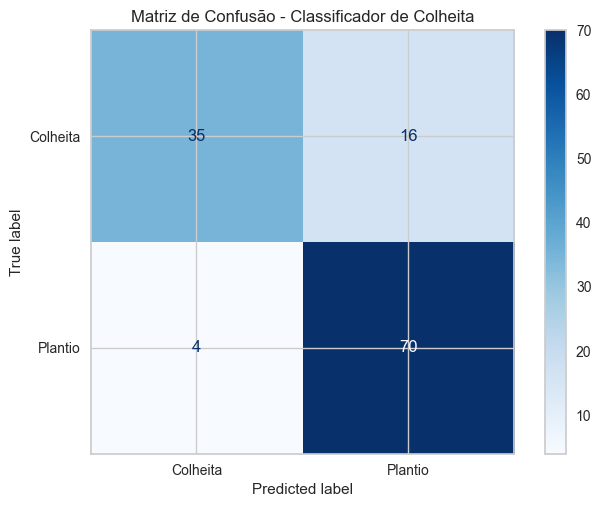

In [73]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

labels = ["Colheita", "Plantio"]
cm = confusion_matrix(soja_teste_real, soja_teste_predito , labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap="Blues")
plt.title("Matriz de Confusão - Classificador de Colheita")
plt.savefig("confusion.png")
plt.show()

In [57]:
cm

array([[35, 16],
       [ 4, 70]], dtype=int64)

In [58]:
VP = cm[0,0]
FP = cm[1,0]
FN = cm[0,1]
VN = cm[1,1]

In [63]:
acuracia = (VP + VN) / (VP + VN + FP + FN)
acuracia

0.84

In [64]:
precisao = VP / (VP + FP) 
precisao

0.8974358974358975

In [65]:
revocacao = VP / (VP + FN)
revocacao

0.6862745098039216

In [66]:
especificidade = VN / (VN + FP)
especificidade

0.9459459459459459

In [68]:
TVP = VP / VP + FN
TFP = FP / FP + VN  
print(TVP, TFP)

17.0 71.0


## OS DADOS ESTÃO EM FORMA CATEGÓRICA, VOU USAR O LABEL ENCODER PRA CORRIGIR

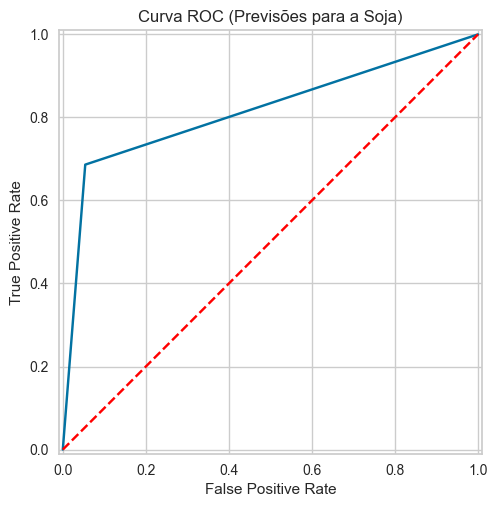

In [74]:
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import RocCurveDisplay, roc_curve

le = LabelEncoder()
le.classes_ = np.array(["Plantio", "Colheita"])

y_encodado_real = le.transform(soja_teste["Estágio Real"])
y_encodado_predito = le.transform(soja_teste["Estágio Previsto"])

tfp, tvp, thresholds = roc_curve(y_encodado_real, y_encodado_predito)

disp = RocCurveDisplay(fpr=tfp, tpr=tvp)
disp.plot()
plt.plot([0, 1], [0, 1], color="red", linestyle="--", label="Chute Aleatório")
plt.title("Curva ROC (Previsões para a Soja)")
plt.savefig("Curva.png")
plt.show()

In [78]:
tfp, tvp

(array([0.        , 0.05405405, 1.        ]),
 array([0.        , 0.68627451, 1.        ]))

In [76]:
from sklearn.metrics import auc, roc_auc_score

auc_score = roc_auc_score(y_encodado_real, y_encodado_predito)
auc_score

0.8161102278749338